# 실험 하네스

**이 노트북에서 할 일**

1. 실습 폴더 설정 파일을 읽고, 검색 개수 하나만 바꾼 실행 설정을 만듭니다.
2. 색인 설정에 이름표를 붙여 문서 18건을 색인하고, Ch 11 평가셋의 Q001로 검색해 답을 받습니다.
3. 설정과 검색 결과와 답을 기록 한 줄로 파일에 쓰고, 다시 읽어 모양을 확인합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 세 가지입니다.

실습 자료 폴더 `labs/data/rag-corpus`의 디지털 PDF 18건과 목록 파일을 읽습니다.
설정은 실습 폴더 `labs/part3/ch09-rag-first-run/config.yaml`에서 읽습니다.
질문은 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`에서 읽습니다.
이 파일들은 읽기만 하고 고치지 않습니다.

인터넷 서비스에 요청을 모두 7번 보냅니다. 임베딩 모델 `text-embedding-3-small`에 6번, `gpt-5.4-mini`에 1번입니다.
임베딩 요청 여섯 번은 색인 두 번과 검색 네 번입니다. 실행 시간은 1분 안팎입니다.

예상 비용은 0.01달러 미만으로 잡았습니다. 색인에 넣는 글이 01~05절보다 많아 색인 요청 한 번의 토큰 수가 큽니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
mini 요금은 Ch 6 06절에서 확인한 값입니다.

**이 노트북은 `labs/part3/ch09-rag-first-run/runs` 폴더에 파일을 씁니다.**
5절이 사본 파일 하나를 새로 만들고, 최신 기록 파일 하나를 바꿔 놓습니다. 다른 폴더의 파일은 바꾸지 않습니다.

**강의와 실습 범위** — 강의 시간에는 2·3·5절(설정 읽기, 색인 이름표, 기록 한 줄)을 설명합니다.
6절 값 바꿔 보기와 Before·After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.17.0, langchain 1.4.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-openai 1.6.0과 langchain-text-splitters 1.1.2입니다.
나머지는 PyYAML 6.0.3, openai 3.8.0, python-dotenv 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

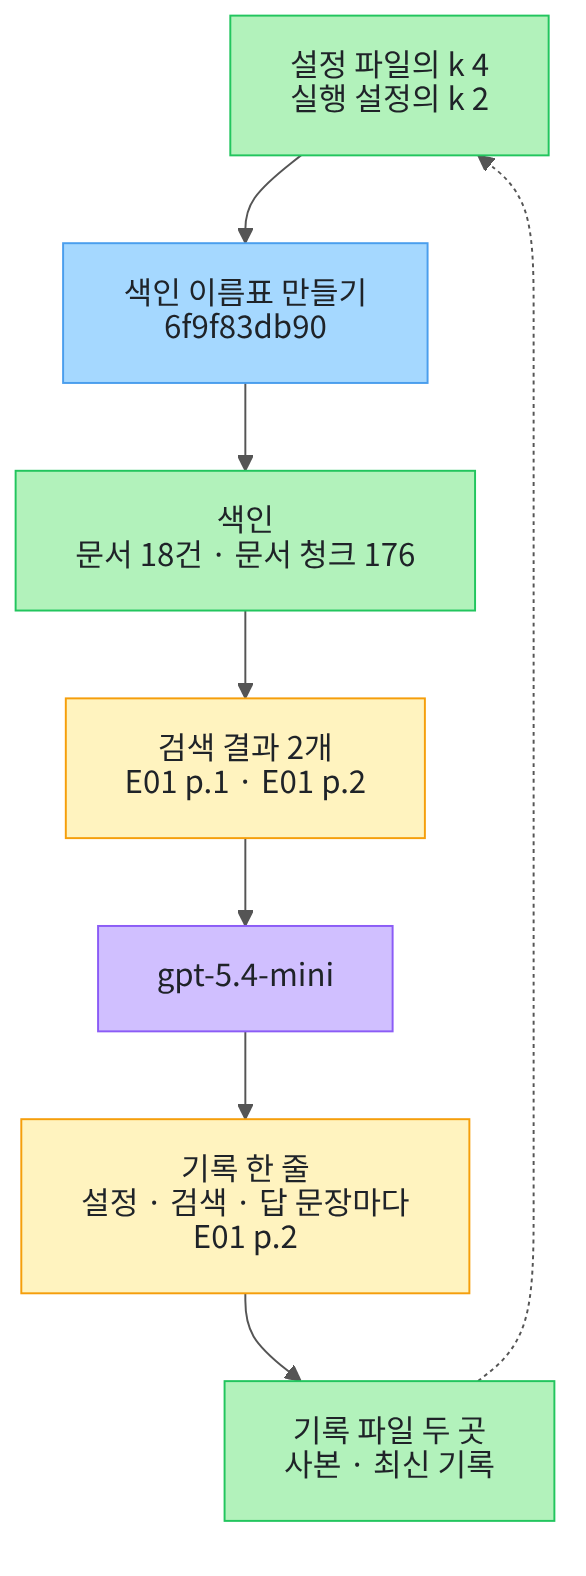

위에서 아래로 읽습니다. 초록 상자는 설정과 색인과 기록 파일이고, 파란 상자는 이름표를 만드는 단계입니다.
노란 상자는 출력으로 확인한 검색 결과와 기록이고, 보라 상자는 실행한 답 모델입니다.
맨 아래에서 맨 위로 돌아가는 점선은 이번 노트북에서 하지 않은 단계입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
05절 패키지에 설정 파일을 읽는 PyYAML 하나를 더했습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3" "pyyaml==6.0.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))
print("PyYAML:", version("pyyaml"))

Note: you may need to restart the kernel to use updated packages.


pypdf: 6.17.0
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2
openai: 3.8.0
python-dotenv: 1.2.3
PyYAML: 6.0.3


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain: 1.4.0`, `PyYAML: 6.0.3` 등 여덟 줄입니다.
준비물에 적은 기준 버전과 같습니다.

설정 읽기, 파일 지문, 실행 이름, 문서 청크 나누기, 검색, 모델 준비에 쓸 이름을 불러옵니다.
모듈 `hashlib`과 `json`은 Ch 7 08절에서, `time`은 Ch 7 08절 실행 이름에서 썼습니다. 패키지 `yaml`은 이 절에서 처음 씁니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `load_pdf_pages()`, 04절 `make_note()`, Ch 8 02·04절 `find_cited_notes()`·`build_notes_messages()`를 가져옵니다.

In [2]:
# 설정 읽기·파일 지문·실행 이름·문서 청크 나누기·검색·모델 준비에 쓸 이름을 불러옵니다
import hashlib
import json
import os
import time

import yaml
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.chat_models import init_chat_model
# 02·04절과 Ch 8 02·04절 함수 네 개를 도구 파일에서 가져옵니다
from rag_tools import build_notes_messages, find_cited_notes, load_pdf_pages, make_note

01·04·05절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


04·05절과 같은 설정으로 답을 쓸 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.
실행마다 답 문장이 달라질 수 있습니다. Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정과 같은 것이 아닙니다.

## 2. 실습 폴더 설정 파일 읽기

바꿀 값이 코드 여러 곳에 흩어져 있으면 무엇을 바꿨는지 나중에 알기 어렵습니다.
그래서 이 챕터 실습 폴더에는 바꿀 값만 모은 설정 파일 `config.yaml`이 있습니다.
먼저 작업 폴더에서 본 실습 폴더 경로의 앞부분을 고릅니다. 01~05절 경로 셀과 같은 방법이고, 읽을 파일이 여러 개라 앞부분만 고릅니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [5]:
# 작업 폴더에서 본 실습 폴더 경로의 앞부분을 후보 세 개 가운데에서 고릅니다
candidates = ["labs/", "../../", "../../../"]
labs_prefix = None
for candidate in candidates:
    if os.path.exists(candidate + "data/rag-corpus/manifest.json"):
        labs_prefix = candidate
        break
assert labs_prefix is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
corpus_path = labs_prefix + "data/rag-corpus/"
config_path = labs_prefix + "part3/ch09-rag-first-run/config.yaml"
queries_path = labs_prefix + "part3/ch11-evaluation/data/evaluation-queries.jsonl"
print("고른 앞부분:", labs_prefix)
print("설정 파일 경로:", config_path)
print("평가셋 경로:", queries_path)

고른 앞부분: ../../../
설정 파일 경로: ../../../part3/ch09-rag-first-run/config.yaml
평가셋 경로: ../../../part3/ch11-evaluation/data/evaluation-queries.jsonl


**결과 읽기** — 출력 줄은 세 줄입니다. 첫 줄은 `고른 앞부분: labs/`이고, 다음 두 줄은 설정 파일과 평가셋 경로입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보가 나옵니다.

설정 파일을 글로 읽고 `yaml.safe_load()`로 딕셔너리로 바꿉니다.
설정 파일 형식 YAML은 들여쓰기로 층을 나타냅니다. 장 볼 목록을 묶음마다 줄여 적은 쪽지와 비슷합니다.
이 파일에서는 `split:` 아래 두 줄이 한 묶음이 되어, 딕셔너리 안의 딕셔너리로 들어옵니다.

실행 전에 예상합니다. 크기와 겹침은 01~05절과 같은 500과 50일 것입니다.

In [6]:
# 실습 폴더 설정 파일을 읽어 딕셔너리로 바꿉니다(요청 없음)
with open(config_path, encoding="utf-8") as file:
    config_text = file.read()
file_config = yaml.safe_load(config_text)
print("설정 파일의 맨 위 키:", file_config.keys())
print("문서 묶음:", file_config["corpus"]["tiers"])
print("크기와 겹침:", file_config["split"])
print("검색 개수:", file_config["retrieval"]["k"])
print("임베딩 모델:", file_config["embedding"]["model"])
print("답 모델:", file_config["generation"]["model"])

설정 파일의 맨 위 키: dict_keys(['name', 'corpus', 'split', 'embedding', 'retrieval', 'generation', 'queries', 'prices'])
문서 묶음: ['easy', 'medium', 'hard']
크기와 겹침: {'chunk_size': 500, 'chunk_overlap': 50}
검색 개수: 4
임베딩 모델: text-embedding-3-small
답 모델: openai:gpt-5.4-mini


**결과 읽기** — 출력 줄은 여섯 줄입니다. 맨 위 키는 `name`·`corpus`·`split`·`embedding`·`retrieval`·`generation`·`queries`·`prices` 여덟 개입니다.
크기와 겹침은 `{'chunk_size': 500, 'chunk_overlap': 50}`으로 01~05절과 같습니다.
검색 개수는 `4`이고 임베딩 모델은 `text-embedding-3-small`입니다.

이 파일에는 이 노트북이 쓰지 않는 묶음도 있습니다. 묶음 `queries`는 실습 폴더 `harness.py`가 질문 여러 개를 한 번에 돌릴 때 쓰는 목록입니다.
묶음 `prices`는 비용을 어림할 때 쓰는 요금표입니다. 이 노트북은 질문 하나만 보내고 비용을 계산하지 않습니다.

이제 이번 실행에 쓸 설정을 따로 만듭니다. 설정 파일은 그대로 두고, 값 하나만 바꾼 실행 설정을 만드는 것입니다.
바꾸는 값은 검색 개수 하나입니다. 이름은 `k2`로 적어 두어 나중에 기록에서 이 실행을 알아볼 수 있게 합니다.

묶음 `generation`에서는 모델 이름만 가져옵니다. 설정 파일의 `prompt` 값은 실습 폴더 `prompts.py`의 글을 고르는 이름이고, 이 노트북은 04·05절 과업 명세를 그대로 씁니다.

실행 전에 예상합니다. 설정 파일의 검색 개수는 4이고 실행 설정의 검색 개수는 2일 것입니다.

In [7]:
# 설정 파일 값을 그대로 쓰고 검색 개수 하나만 2로 바꾼 실행 설정을 만듭니다(요청 없음)
run_config = {"name": "k2",
              "corpus": file_config["corpus"],
              "split": file_config["split"],
              "embedding": file_config["embedding"],
              "retrieval": {"k": 2},
              "generation": {"model": file_config["generation"]["model"]}}
print("설정 파일의 검색 개수:", file_config["retrieval"]["k"])
print("실행 설정의 검색 개수:", run_config["retrieval"]["k"])
print("실행 설정 이름:", run_config["name"])
print("실행 설정의 키:", run_config.keys())

설정 파일의 검색 개수: 4
실행 설정의 검색 개수: 2
실행 설정 이름: k2
실행 설정의 키: dict_keys(['name', 'corpus', 'split', 'embedding', 'retrieval', 'generation'])


**결과 읽기** — 출력 줄은 네 줄입니다. 설정 파일의 검색 개수는 `4`이고 실행 설정의 검색 개수는 `2`입니다.
실행 설정 이름은 `k2`이고, 키는 여섯 개입니다.
파일에서 읽은 값 가운데 `queries`와 `prices`는 실행 설정에 넣지 않았습니다.

설정 파일은 고치지 않았습니다. 실습 폴더 `harness.py`와 그 테스트가 같은 파일을 읽기 때문입니다.

## 3. 색인 설정에 이름표 붙이기

색인을 다시 만들려면 문서를 다시 나누고 임베딩 요청을 다시 보내야 합니다.
그래서 같은 설정이면 색인을 다시 만들지 않는 것이 좋습니다. 이때 「같은 설정」인지 가려 주는 짧은 글이 색인 이름표입니다.
Ch 7 08절 파일 지문과 같은 SHA-256으로 만들지만, 파일이 아니라 설정 묶음에서 만들고 앞 10자만 씁니다.

함수 `json.dumps()`에 `sort_keys=True`를 주면 키를 이름 순서로 놓은 글을 만듭니다.
같은 설정을 적는 순서가 달라도 같은 글이 되고, 따라서 같은 이름표가 나옵니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [8]:
# 색인 설정 묶음을 받아 앞 10자 이름표를 반환하는 함수를 정의합니다
def make_index_key(index_settings):
    settings_text = json.dumps(index_settings, sort_keys=True)
    settings_bytes = settings_text.encode("utf-8")
    long_key = hashlib.sha256(settings_bytes).hexdigest()
    return long_key[:10]

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

이름표에 넣을 설정은 색인 결과를 바꾸는 것만 고릅니다. 어느 문서를 넣는지, 어떻게 나누는지, 어느 임베딩 모델을 쓰는지입니다.
검색 개수는 넣지 않습니다. 이미 만든 색인에서 몇 건을 가져올지만 바꾸기 때문입니다.

답 모델도 넣지 않습니다. 답을 쓰는 단계는 색인 뒤에 오기 때문입니다.

실행 전에 예상합니다. 이름표는 10자 글이고, 설정 글의 키는 `corpus`·`embedding`·`split` 순서일 것입니다.

In [9]:
# 색인 결과를 바꾸는 설정만 골라 이름표를 만듭니다(요청 없음)
index_settings = {"corpus": run_config["corpus"],
                  "split": run_config["split"],
                  "embedding": run_config["embedding"]}
settings_text = json.dumps(index_settings, sort_keys=True)
index_key = make_index_key(index_settings)
print("색인 설정 글:", settings_text)
print("색인 이름표:", index_key)

색인 설정 글: {"corpus": {"tiers": ["easy", "medium", "hard"]}, "embedding": {"model": "text-embedding-3-small"}, "split": {"chunk_overlap": 50, "chunk_size": 500}}
색인 이름표: 6f9f83db90


**결과 읽기** — 출력 줄은 두 줄입니다. 설정 글의 키는 `corpus`·`embedding`·`split` 순서로 놓였습니다.
색인 이름표는 `6f9f83db90`입니다. 같은 설정에서는 언제 만들어도 같은 이름표가 나옵니다.

이름표를 문서 청크 이름에 적어 두면, 기록만 보고도 어느 색인에서 나온 결과인지 알 수 있습니다.

색인에 넣을 문서를 정합니다. 실습 자료 폴더에는 문서마다 이름·묶음·제목·파일 경로를 적은 목록 파일 `manifest.json`이 있습니다.
설정의 `corpus.tiers`에 적힌 묶음에 든 항목만 고릅니다. 스캔 문서 묶음은 설정에 없어서 빠집니다.

실행 전에 예상합니다. 목록에는 스캔 문서까지 있고, 고른 문서는 18건일 것입니다.

In [10]:
# 설정의 문서 묶음에 든 문서를 실습 자료 목록에서 모읍니다(요청 없음)
with open(corpus_path + "manifest.json", encoding="utf-8") as file:
    manifest_text = file.read()
manifest = json.loads(manifest_text)
picked_docs = []
doc_names = []
for item in manifest:
    if item["tier"] in run_config["corpus"]["tiers"]:
        picked_docs.append(item)
        doc_names.append(item["doc_id"])
print("자료 목록 항목 수:", len(manifest))
print("색인에 넣을 문서 수:", len(picked_docs))
print("문서 이름:", doc_names)
print("첫 문서의 파일 경로:", picked_docs[0]["file"])

자료 목록 항목 수: 21
색인에 넣을 문서 수: 18
문서 이름: ['E01', 'E02', 'E03', 'E04', 'E05', 'E06', 'H01', 'H02', 'H03', 'H04', 'H05', 'H06', 'M01', 'M02', 'M03', 'M04', 'M05', 'M06']
첫 문서의 파일 경로: pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 네 줄입니다. 자료 목록 항목 수는 `21`이고 색인에 넣을 문서 수는 `18`입니다.
빠진 세 건은 스캔 문서 묶음이라 설정의 문서 묶음 목록에 없습니다.
첫 문서의 파일 경로는 `pdf/easy/E01.pdf`로, 01~05절에서 읽은 문서와 같습니다.

문서 이름은 E01부터 M06까지 열여덟 개입니다. 01~05절은 E01 한 건만 색인했습니다.
문서가 여러 건이라 정답 문서 ID 대조에 뜻이 생깁니다. 검색이 E01을 나머지 열일곱 건보다 앞에 놓아야 맞습니다.

문서는 준비 셀에서 가져온 02절 로더 함수 `load_pdf_pages()`로 읽습니다.
PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.
메타데이터에는 문서 이름 `doc_id`, 쪽 번호 `page`, 파일 이름 `source` 세 키를 적습니다.

고른 문서 18건을 모두 읽고, 실행 설정의 크기와 겹침으로 나눕니다.
그다음 문서 청크마다 `chunk_id` 키를 하나 더 적습니다. 값은 색인 이름표와 순서 번호를 이은 글입니다.
나중에 기록만 보고도 그 검색 결과가 어느 색인에서 나왔는지 알아볼 수 있게 하려는 것입니다.

실행 전에 예상합니다. 01~05절과 같은 500자·50자 설정이라, E01의 첫 문서 청크는 표지 45자일 것입니다.

In [11]:
# 고른 문서를 모두 읽어 쪽마다 Document를 만들고, 실행 설정대로 나눠 chunk_id를 적습니다(요청 없음)
pages = []
for item in picked_docs:
    pages = pages + load_pdf_pages(corpus_path + item["file"], item["doc_id"])
splitter = RecursiveCharacterTextSplitter(chunk_size=run_config["split"]["chunk_size"],
                                          chunk_overlap=run_config["split"]["chunk_overlap"])
chunks = splitter.split_documents(pages)
number = 0
for chunk in chunks:
    chunk.metadata["chunk_id"] = "ch09:" + index_key + ":" + str(number)
    number = number + 1
print("Document 수:", len(pages))
print("문서 청크 수:", len(chunks))
print("첫 문서 청크의 글자 수:", len(chunks[0].page_content))
print("첫 문서 청크의 메타데이터:", chunks[0].metadata)

Document 수: 93
문서 청크 수: 176
첫 문서 청크의 글자 수: 45
첫 문서 청크의 메타데이터: {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf', 'chunk_id': 'ch09:6f9f83db90:0'}


**결과 읽기** — 출력 줄은 네 줄입니다. 쪽마다 만든 Document 수는 `93`이고 문서 청크 수는 `176`입니다.
첫 문서 청크의 글자 수는 `45`로, 01~05절에서 본 E01 표지와 같습니다.
메타데이터에는 `chunk_id` 값 `ch09:6f9f83db90:0`이 더 붙었습니다.

문서 청크 이름은 색인 이름표와 순서 번호를 이은 글입니다. 문서 E01은 목록의 첫 문서라 번호 0부터 받습니다.

03~05절과 같은 방법으로 빈 벡터스토어를 만들어 문서 청크를 넣습니다. 임베딩 객체 이름도 `embedding_model`로 같습니다.
문서 청크 수가 01~05절의 8개보다 많지만, `add_documents()`는 여러 글을 한 요청으로 보냅니다(03절 설치판 확인).

실행 전에 예상합니다. 저장 항목 수는 문서 청크 수와 같을 것입니다.

In [12]:
# 문서 청크를 벡터스토어에 넣습니다(임베딩 요청 1번)
embedding_model = OpenAIEmbeddings(model=run_config["embedding"]["model"])
store = InMemoryVectorStore(embedding=embedding_model)
stored_ids = store.add_documents(chunks)
print("저장 ID 수:", len(stored_ids))
print("넣은 뒤 저장 항목 수:", len(store.store))

저장 ID 수: 176
넣은 뒤 저장 항목 수: 176


**결과 읽기** — 출력 줄은 두 줄입니다. 저장 ID 수와 저장 항목 수가 모두 `176`으로 문서 청크 수와 같습니다.
임베딩 요청은 한 번이었습니다. 문서 청크를 한 요청에 담아 보냈기 때문입니다.

01~05절 색인은 문서 청크 8개였습니다. 이번 색인은 글이 많아 요청 한 번의 토큰 수가 큽니다.

## 4. 평가셋에서 질문과 정답 문서 ID 가져오기

기록 한 줄에는 질문과 정답 문서 ID도 함께 적습니다. 이 두 값은 실행 설정이 아니라 사람이 미리 붙여 둔 라벨입니다.
시험지에 답안을 매기기 전에 정답표를 따로 만들어 두는 것과 비슷합니다.
그래서 이 노트북이 글을 새로 적지 않고, Ch 11 평가셋 파일에서 그대로 읽어 옵니다.
평가셋과 글자가 한 자라도 다르면 Ch 11이 두 값을 짝지을 수 없기 때문입니다.

평가셋은 한 줄에 JSON 하나를 둔 파일입니다. 공책 한 줄에 기록 하나씩 적어 내려가는 것과 비슷합니다. 첫 줄이 Q001입니다.
실행 전에 예상합니다. 정답 문서 ID는 원소 하나짜리 목록 `['E01']`일 것입니다.

In [13]:
# Ch 11 평가셋의 첫 줄에서 Q001을 읽습니다(요청 없음)
with open(queries_path, encoding="utf-8") as file:
    queries_text = file.read()
query_lines = queries_text.split("\n")
query = json.loads(query_lines[0])
print("질문 ID:", query["qid"])
print("질문:", query["question"])
print("정답 문서 ID:", query["gold_doc_ids"])
print("나눔 이름:", query["split"])

질문 ID: Q001
질문: 미르시립도서관의 정기 휴관일은 언제인가요?
정답 문서 ID: ['E01']
나눔 이름: dev


**결과 읽기** — 출력 줄은 네 줄입니다. 질문 ID는 `Q001`이고 정답 문서 ID는 `['E01']`입니다.
질문은 `미르시립도서관의 정기 휴관일은 언제인가요?`이고 나눔 이름은 `dev`입니다.

이 질문은 01·05절에서 쓴 휴관일 질문보다 짧습니다. 01·05절 질문에는 공휴일 조건이 한 문장 더 붙어 있었습니다.
이 절 기록은 Ch 11 평가셋과 짝지어야 해서, 평가셋에 적힌 글을 그대로 씁니다.
나눔 이름 `dev`는 설정을 고를 때 쓰는 질문 묶음이라는 표시입니다.

같은 질문이 실습 자료 폴더의 질문 목록에도 있습니다. 그 파일에는 정답 쪽까지 적혀 있습니다.
05절에서 사람이 적은 정답 출처는 `E01 p.2`처럼 쪽 단위였습니다. 이 절 기록과 Ch 11 평가셋의 정답 문서 ID는 `E01`처럼 문서 단위입니다.

두 말은 같은 질문을 가리키지만 단위가 다릅니다. 문서 단위로 보면, 05절 2쪽 452자 기록처럼 같은 문서의 다른 부분이 올라와도 맞다고 나옵니다.

실행 전에 예상합니다. 두 파일의 질문 글은 같을 것입니다.

In [14]:
# 실습 자료의 질문 목록에서 같은 질문을 찾아 정답 쪽까지 봅니다(요청 없음)
with open(corpus_path + "queries.jsonl", encoding="utf-8") as file:
    corpus_lines = file.read().split("\n")
corpus_query = json.loads(corpus_lines[0])
print("질문 ID:", corpus_query["qid"])
print("정답 문서:", corpus_query["doc_id"])
print("정답 쪽:", corpus_query["gold_pages"])
print("두 파일의 질문 글이 같은가:", corpus_query["question"] == query["question"])

질문 ID: Q001
정답 문서: E01
정답 쪽: [2]
두 파일의 질문 글이 같은가: True


**결과 읽기** — 출력 줄은 네 줄입니다. 정답 문서는 `E01`이고 정답 쪽은 `[2]`입니다.
마지막 줄은 `두 파일의 질문 글이 같은가: True`입니다. 두 파일이 같은 질문을 가리킨다는 뜻입니다.

05절 정답 출처 `E01 p.2`는 쪽까지 적은 값입니다. 이 절 기록의 정답 문서 ID는 문서까지만 적은 값입니다.
문서 단위로 보면 E01의 어느 쪽이 올라와도 맞다고 나옵니다. 05절에서 본 2쪽 452자 기록이 그런 경우입니다.
쪽까지 맞는지는 05절 방법으로 따로 봅니다.

기록에는 두 입력 파일의 지문도 함께 남깁니다. 같은 설정이라도 문서나 평가셋이 바뀌면 결과가 달라지기 때문입니다.
Ch 7 08절에서 본 것처럼 글을 UTF-8 바이트로 바꾼 뒤 `hashlib.sha256()`으로 지문을 냅니다.
지문은 64글자라 출력에서는 앞 10자만 봅니다.

실행 전에 예상합니다. 지문 글자 수는 64일 것입니다.

In [15]:
# 색인에 넣은 자료 목록과 평가셋의 파일 지문을 냅니다(Ch 7 08절과 같은 방법, 요청 없음)
manifest_bytes = manifest_text.encode("utf-8")
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
queries_bytes = queries_text.encode("utf-8")
dataset_sha256 = hashlib.sha256(queries_bytes).hexdigest()
corpus_scope = "디지털 PDF " + str(len(picked_docs)) + "건"
print("자료 목록 지문의 앞 10자:", manifest_sha256[:10])
print("평가셋 지문의 앞 10자:", dataset_sha256[:10])
print("지문 글자 수:", len(manifest_sha256))
print("적어 둘 문서 범위:", corpus_scope)

자료 목록 지문의 앞 10자: 27541f4121
평가셋 지문의 앞 10자: 9544b332d5
지문 글자 수: 64
적어 둘 문서 범위: 디지털 PDF 18건


**결과 읽기** — 출력 줄은 네 줄입니다. 자료 목록 지문의 앞 10자는 `27541f4121`이고 평가셋 지문의 앞 10자는 `9544b332d5`입니다.
지문 글자 수는 `64`이고, 적어 둘 문서 범위는 `디지털 PDF 18건`입니다.

Ch 7 08절에서는 지문을 자르지 않고 64글자를 그대로 썼습니다. 색인 이름표만 앞 10자로 줄여 씁니다.

## 5. 검색하고 답을 받아 기록 한 줄 만들기

이제 실행 설정의 검색 개수로 Q001을 검색합니다. 03~05절과 같은 `similarity_search_with_score()`를 씁니다.
점수는 실행마다 소수 넷째 자리가 달라질 수 있습니다(03절 확인). 그래서 아래 출력에서는 점수 값보다 순서를 봅니다.

실행 전에 예상합니다. 문서 18건을 넣었지만 1·2위는 01~05절에서 본 E01 표지와 2쪽일 것입니다.

In [16]:
# Q001을 실행 설정의 검색 개수로 검색합니다(임베딩 요청 1번)
hits = store.similarity_search_with_score(query["question"], k=run_config["retrieval"]["k"])
print("검색 결과 수:", len(hits))
print("검색 결과(출처 | 글자 수 | 점수):")
for hit, score in hits:
    print(hit.metadata["doc_id"], "p." + str(hit.metadata["page"]), "|",
          len(hit.page_content), "|", round(score, 4))

검색 결과 수: 2
검색 결과(출처 | 글자 수 | 점수):
E01 p.1 | 45 | 0.6492
E01 p.2 | 498 | 0.5652


**결과 읽기** — 출력의 첫 줄은 `검색 결과 수: 2`입니다. 라벨 줄 아래 첫 줄은 `E01 p.1 | 45`로 시작하고, 둘째 줄은 `E01 p.2 | 498`로 시작합니다.
문서 18건을 넣었지만 1·2위는 모두 E01이었습니다. 두 문서 청크는 01~05절에서 본 표지 45자와 2쪽 498자입니다.

점수는 소수 넷째 자리가 실행마다 달라집니다. 그래서 값을 그대로 외지 않고 순서만 봅니다.
표지 45자가 1위인 것은 03·05절에서도 본 결과입니다. 표지에는 휴관 이야기가 없습니다.

검색 결과를 모델에 넣을 기록으로 옮길 때는 준비 셀에서 가져온 04절 `make_note()`를 씁니다. 문서 청크 하나를 출처와 내용 두 키를 가진 기록으로 바꿉니다.

기록 파일에 적을 검색 항목은 기록과 모양이 다릅니다. 본문 글은 넣지 않고, 문서 이름·문서 청크 이름·쪽 번호·순위·점수만 넣습니다.
Ch 11이 순위와 문서 이름으로 검색 지표를 계산하기 때문입니다. 본문을 넣지 않아 파일도 짧게 남습니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [17]:
# 검색 결과 하나를 기록 파일에 적을 검색 항목으로 바꾸는 함수를 정의합니다
def make_hit_item(hit, score, rank):
    metadata = hit.metadata
    item = {"doc_id": metadata["doc_id"], "chunk_id": metadata["chunk_id"],
            "page": metadata["page"], "rank": rank, "score": round(score, 4)}
    return item

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

검색 결과를 두 가지로 옮깁니다. 모델에 넣을 기록 목록과, 기록 파일에 적을 검색 항목 목록입니다.
순위는 1부터 셉니다. Ch 11이 순위가 1부터 차례인지 확인하기 때문입니다.

실행 전에 예상합니다. 검색 출처는 `['E01 p.1', 'E01 p.2']`일 것입니다.

In [18]:
# 검색 결과를 04·05절 기록과, 기록 파일에 적을 검색 항목으로 옮깁니다(요청 없음)
notes = []
sources = []
retrieved = []
rank = 1
for hit, score in hits:
    note = make_note(hit)
    notes.append(note)
    sources.append(note["출처"])
    retrieved.append(make_hit_item(hit, score, rank))
    rank = rank + 1
print("기록 수:", len(notes))
print("검색 출처:", sources)
print("첫 검색 항목:", retrieved[0])

기록 수: 2
검색 출처: ['E01 p.1', 'E01 p.2']
첫 검색 항목: {'doc_id': 'E01', 'chunk_id': 'ch09:6f9f83db90:0', 'page': 1, 'rank': 1, 'score': 0.6492}


**결과 읽기** — 출력 줄은 세 줄입니다. 기록 수는 `2`이고 검색 출처는 `['E01 p.1', 'E01 p.2']`입니다.
첫 검색 항목에는 `'doc_id': 'E01'`과 `'rank': 1`이 있습니다. 본문 글은 들어 있지 않습니다.

기록에는 본문이 있고 검색 항목에는 없습니다. 모델에는 본문이 필요하고, Ch 11에는 순위와 문서 이름이 필요하기 때문입니다.

페르소나와 과업 명세는 05절과 같은 글입니다. 04절 글에 Ch 5 07절 보류 지시 한 문장을 더한 것입니다.
질문 Q001은 E01에 답이 있는 질문이라, 이번에는 보류 지시가 걸리지 않을 것으로 봅니다.

실행 전에 예상합니다. 과업 명세는 05절과 같은 세 문장일 것입니다.

In [19]:
# 05절과 같은 페르소나와 과업 명세를 적습니다(요청 없음)
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요."
task_text = task_text + " 근거에 답이 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요. 근거에 답이 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요.


**결과 읽기** — 출력 줄은 두 줄입니다. 과업 명세에는 `두 문장 이내로 답하고`와 `근거 앞에 붙은 출처 표시를 그대로 적으세요`가 있습니다.
끝에는 05절에서 더한 보류 지시 `제공된 정보로는 확인할 수 없습니다`가 있습니다.

페르소나는 Ch 8과 01·04·05절에서 쓴 글과 같습니다.

메시지 목록은 04·05절처럼 준비 셀에서 가져온 `build_notes_messages()`로 만듭니다. 기록마다 출처 표시를 앞에 붙여 근거 글을 만들고, 질문을 뒤에 잇습니다.
페르소나와 과업 명세는 앞의 두 인자로 넘깁니다.

검색 결과 두 건을 근거로 넣어 답을 받습니다. 이 노트북의 답 모델 요청은 이 셀 한 번뿐입니다.
입력 토큰 수도 함께 봅니다. 검색 개수를 늘려 근거 글이 길어지면 이 값이 커집니다.

실행 전에 예상합니다. 답 끝에는 2쪽 출처 표시가 붙을 것입니다.

In [20]:
# 검색 근거가 든 메시지 목록으로 답을 받습니다(gpt-5.4-mini 요청 1번)
messages = build_notes_messages(persona_text, task_text, notes, query["question"])
response = model.invoke(messages)
answer_text = response.text
input_tokens = response.usage_metadata["input_tokens"]
print("메시지 수:", len(messages))
print("실제 입력 토큰 수:", input_tokens)
print("답:")
print(answer_text)

메시지 수: 3
실제 입력 토큰 수: 499
답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. [E01 p.2]


**결과 읽기** — 출력의 첫 줄은 `메시지 수: 3`이고 둘째 줄은 `실제 입력 토큰 수: 499`입니다.

라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다. [E01 p.2] 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]`입니다.

답은 두 문장이고 문장마다 끝에 2쪽 출처 표시가 붙었습니다. 보류 문장은 없었습니다.
실행마다 답 문장이 달라질 수 있습니다.

과업 명세는 두 문장 이내로 답하고 문장마다 출처 표시를 적으라고 했습니다. 이번 답은 그대로 두 문장에 표시를 하나씩 붙였습니다.
01·04절 답은 표시를 문장마다 붙이지 않고 끝에 모았습니다. 같은 과업 명세에서도 답 모양이 달라집니다.
근거에 함께 든 표지 표시 `[E01 p.1]`은 답에 없었습니다.

이제 기록 한 줄을 모읍니다. 한 줄에 네 가지를 함께 적습니다.
평가셋에서 읽은 라벨, 이번 실행 설정, 검색 항목 목록, 답입니다.
설정 안에는 입력 파일 지문도 넣어 어느 자료로 실행했는지 남깁니다.

실행 이름은 실행한 시각으로 만듭니다. 그래서 실행마다 다른 글이 되고, 사본 파일 이름으로도 씁니다.
실행 전에 예상합니다. 기록의 키는 여덟 개일 것입니다.

In [21]:
# 라벨과 실행 설정과 검색 결과와 답을 기록 한 줄로 모읍니다(요청 없음)
input_record = {"corpus_scope": corpus_scope, "corpus_manifest_sha256": manifest_sha256,
                "evaluation_dataset_sha256": dataset_sha256}
logged_config = {"name": run_config["name"], "corpus": run_config["corpus"],
                 "split": run_config["split"], "embedding": run_config["embedding"],
                 "retrieval": run_config["retrieval"], "generation": run_config["generation"],
                 "inputs": input_record}
source_run_id = time.strftime("%Y%m%dT%H%M%S") + "-ch09"
record = {"qid": query["qid"], "question": query["question"],
          "gold_doc_ids": query["gold_doc_ids"], "source_chapter": "ch09",
          "source_run_id": source_run_id, "config": logged_config,
          "retrieved": retrieved, "answer": answer_text}
print("설정의 키:", logged_config.keys())
print("기록의 키:", record.keys())

설정의 키: dict_keys(['name', 'corpus', 'split', 'embedding', 'retrieval', 'generation', 'inputs'])
기록의 키: dict_keys(['qid', 'question', 'gold_doc_ids', 'source_chapter', 'source_run_id', 'config', 'retrieved', 'answer'])


**결과 읽기** — 출력 줄은 두 줄입니다. 설정의 키는 일곱 개이고, 마지막 키 `inputs`에 입력 파일 지문이 들어 있습니다.
기록의 키는 여덟 개입니다. 목록은 `qid`, `question`, `gold_doc_ids`, `source_chapter`, `source_run_id`, `config`, `retrieved`, `answer`입니다.

설정 안에는 질문과 정답 문서 ID를 넣지 않았습니다. 라벨과 설정을 섞으면 무엇을 바꿔서 결과가 달라졌는지 읽기 어렵습니다.
Ch 11 검사도 설정 안에 라벨이 있으면 멈춥니다.

답의 출처 표시는 준비 셀에서 가져온 Ch 8 02절 `find_cited_notes()`로 봅니다. 답 글에 출처 표시가 들어 있는 기록만 모읍니다.

파일에 쓰기 전에 기록이 다음 챕터가 읽는 모양인지 확인합니다. 세 가지를 봅니다.
필수 키가 모두 있는지, 순위가 1부터 차례인지, 답에 근거의 출처 표시가 있는지입니다.
Ch 11 검사는 이 세 가지가 어긋나면 멈춥니다. 그래서 어긋난 기록을 파일에 남기지 않는 것이 좋습니다.

실행 전에 예상합니다. 빠진 필수 키는 빈 목록일 것입니다.

In [22]:
# 기록이 다음 챕터가 읽는 모양인지 세 가지로 확인합니다(요청 없음)
record_keys = ["qid", "question", "gold_doc_ids", "source_chapter",
               "source_run_id", "config", "retrieved", "answer"]
missing_keys = []
for key in record_keys:
    if key not in record:
        missing_keys.append(key)
record_ranks = []
for item in record["retrieved"]:
    record_ranks.append(item["rank"])
cited_notes = find_cited_notes(record["answer"], notes)
print("기록에서 빠진 필수 키:", missing_keys)
print("검색 항목의 순위:", record_ranks)
print("답에 쓰인 출처 표시 수:", len(cited_notes))

기록에서 빠진 필수 키: []
검색 항목의 순위: [1, 2]
답에 쓰인 출처 표시 수: 1


**결과 읽기** — 출력 줄은 세 줄입니다. 빠진 필수 키는 `[]`이고 검색 항목의 순위는 `[1, 2]`입니다.
답에 쓰인 출처 표시 수는 `1`입니다. 기록 두 개 가운데 2쪽 하나만 답에 표시되었습니다.

이 검사는 모양만 봅니다. 출처 표시가 답 내용을 뒷받침하는지는 04·05절처럼 사람이 원문과 대조해야 합니다.

이제 파일에 씁니다. 두 곳에 씁니다.
첫째는 실행 이름이 붙은 사본 파일입니다. 실행마다 새 파일이 생기고, 앞 실행 기록을 덮어쓰지 않습니다.

둘째는 이름이 고정된 최신 기록 파일입니다. 다음 챕터는 이 파일만 읽습니다.

최신 기록 파일은 임시 이름으로 다 쓴 뒤 `os.replace()`로 이름만 바꿉니다.
설치판 설명에 따르면 이 함수는 파일 이름을 바꾸고 같은 이름이 있으면 덮어씁니다.
다른 챕터가 읽는 파일이라, 쓰는 도중의 글을 읽는 일을 줄이려고 이렇게 씁니다.
운영체제마다 이것이 얼마나 보장되는지는 이번에 확인하지 않았습니다.

실행 전에 예상합니다. 임시 파일은 이름을 바꾼 뒤 남지 않을 것입니다.

In [23]:
# 기록 한 줄을 사본 파일과 최신 기록 파일 두 곳에 씁니다(요청 없음)
runs_path = labs_prefix + "part3/ch09-rag-first-run/runs"
record_line = json.dumps(record, ensure_ascii=False) + "\n"
archive_folder = runs_path + "/continuity"
if not os.path.exists(archive_folder):
    os.makedirs(archive_folder)
archive_path = archive_folder + "/" + source_run_id + ".jsonl"
with open(archive_path, "w", encoding="utf-8") as file:
    file.write(record_line)
temp_path = runs_path + "/continuity-ch09-search.tmp"
pointer_path = runs_path + "/continuity-ch09-search.jsonl"
with open(temp_path, "w", encoding="utf-8") as file:
    file.write(record_line)
os.replace(temp_path, pointer_path)
print("기록 한 줄의 글자 수:", len(record_line))
print("임시 파일이 남았는가:", os.path.exists(temp_path))

기록 한 줄의 글자 수: 876
임시 파일이 남았는가: False


**결과 읽기** — 출력 줄은 두 줄입니다. 첫 줄은 기록 한 줄의 글자 수이고, 답 문장 길이에 따라 실행마다 달라집니다.
둘째 줄은 `임시 파일이 남았는가: False`입니다. 이름을 바꿔서 임시 이름이 사라졌다는 뜻입니다.

사본 파일은 실행 이름으로 만들어지고, 최신 기록 파일은 이름이 고정됩니다.
앞 실행 사본은 그대로 남고, 최신 기록 파일만 이번 실행 기록으로 바뀝니다.

쓴 파일을 다시 읽어 네 가지를 확인합니다. 질문 ID, 정답 문서 ID, 검색 항목 수, 답입니다.
다시 읽은 값이 앞 셀에서 만든 값과 같으면, 파일에 제대로 남았다고 봅니다.

실행 전에 예상합니다. 다시 읽은 검색 항목 수는 2일 것입니다.

In [24]:
# 최신 기록 파일을 다시 읽어 다음 챕터가 볼 값을 확인합니다(요청 없음)
with open(pointer_path, encoding="utf-8") as file:
    saved_text = file.read()
saved = json.loads(saved_text)
print("질문 ID:", saved["qid"])
print("정답 문서 ID:", saved["gold_doc_ids"])
print("검색 항목 수:", len(saved["retrieved"]))
print("첫 검색 항목의 chunk_id:", saved["retrieved"][0]["chunk_id"])
print("답:")
print(saved["answer"])

질문 ID: Q001
정답 문서 ID: ['E01']
검색 항목 수: 2
첫 검색 항목의 chunk_id: ch09:6f9f83db90:0
답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. [E01 p.2]


**결과 읽기** — 출력 줄은 다섯 줄입니다. 질문 ID는 `Q001`, 정답 문서 ID는 `['E01']`, 검색 항목 수는 `2`입니다.
첫 검색 항목의 `chunk_id`는 `ch09:6f9f83db90:0`입니다. 라벨 줄 아래 답은 앞 셀에서 받은 답과 같습니다.

파일에 쓴 값이 그대로 다시 읽혔습니다. 다음 챕터는 이 파일에서 질문과 정답 문서 ID와 검색 항목을 읽습니다.

## 6. 값 바꿔 보기 — 검색 개수만 4로

실행 설정에서 검색 개수만 4로 바꿉니다. 설정 파일의 기본값과 같은 값입니다.
색인 이름표에 검색 개수를 넣지 않았으니 이름표는 그대로일 것입니다. 그러면 색인을 다시 만들지 않고 검색만 다시 합니다.

이 셀은 기록 파일을 쓰지 않습니다. 최신 기록 파일은 5절에서 쓴 실행 하나를 그대로 가리킵니다.

실행 전에 예상합니다. 이름표는 같고 검색 결과는 4건일 것입니다.

In [25]:
# 검색 개수만 4로 바꾼 실행 설정으로 색인 이름표와 검색 결과를 봅니다(임베딩 요청 1번)
wide_config = {"name": "k4", "corpus": run_config["corpus"], "split": run_config["split"],
               "embedding": run_config["embedding"], "retrieval": {"k": 4},
               "generation": run_config["generation"]}
wide_settings = {"corpus": wide_config["corpus"], "split": wide_config["split"],
                 "embedding": wide_config["embedding"]}
wide_key = make_index_key(wide_settings)
wide_hits = store.similarity_search_with_score(query["question"], k=wide_config["retrieval"]["k"])
print("색인 이름표가 같은가:", wide_key == index_key)
print("검색 결과 수:", len(wide_hits))
print("검색 결과(출처 | 글자 수 | 점수):")
for hit, score in wide_hits:
    print(hit.metadata["doc_id"], "p." + str(hit.metadata["page"]), "|",
          len(hit.page_content), "|", round(score, 4))

색인 이름표가 같은가: True
검색 결과 수: 4
검색 결과(출처 | 글자 수 | 점수):
E01 p.1 | 45 | 0.6492
E01 p.2 | 498 | 0.5652
M04 p.3 | 493 | 0.4936
H03 p.2 | 485 | 0.464


**결과 읽기** — 출력의 첫 줄은 `색인 이름표가 같은가: True`이고 둘째 줄은 `검색 결과 수: 4`입니다.
라벨 줄 아래 3위는 `M04 p.3 | 493`으로, 4위는 `H03 p.2 | 485`로 시작합니다.
1·2위는 5절과 같은 E01 두 건이었습니다.

검색 개수를 늘리자 정답 문서가 아닌 문서 두 건이 들어왔습니다. 그래도 색인은 다시 만들지 않았습니다.
검색 개수가 이름표에 들어 있지 않기 때문입니다. 늘어난 근거가 답을 어떻게 바꾸는지는 이번에 실행하지 않았습니다.

## Before — 설정만 바꾸고 색인은 그대로 쓰기

실패 조건은 이렇습니다. 문서 청크 크기를 1000으로 바꾼 실행 설정을 만들고, 색인은 500자로 만든 것을 그대로 씁니다.
검색은 문제없이 끝나고 기록도 만들어집니다. 그런데 기록에 적힌 설정과 실제로 검색한 색인이 서로 다릅니다.

이 어긋남은 검색 항목의 `chunk_id`로 잡을 수 있습니다. 바꾼 설정으로 만든 이름표가 `chunk_id` 안에 있는지 보면 됩니다.
두 조건 Before와 After 모두 기록 파일을 쓰지 않습니다. 검색 개수는 두 조건 모두 2로 둡니다.

실행 전에 예상합니다. 바꾼 설정의 이름표는 `chunk_id`에 없을 것입니다.

In [26]:
# 문서 청크 크기만 1000으로 바꾸고, 500자로 만든 색인을 그대로 써서 검색합니다(임베딩 요청 1번)
before_split = {"chunk_size": 1000, "chunk_overlap": 50}
before_settings = {"corpus": run_config["corpus"], "split": before_split,
                   "embedding": run_config["embedding"]}
before_key = make_index_key(before_settings)
before_hits = store.similarity_search_with_score(query["question"], k=2)
before_retrieved = []
rank = 1
for hit, score in before_hits:
    before_retrieved.append(make_hit_item(hit, score, rank))
    rank = rank + 1
print("바꾼 설정의 색인 이름표:", before_key)
print("첫 검색 항목의 chunk_id:", before_retrieved[0]["chunk_id"])
print("이름표가 chunk_id에 들어 있는가:", before_key in before_retrieved[0]["chunk_id"])

바꾼 설정의 색인 이름표: 9fa7a45db1
첫 검색 항목의 chunk_id: ch09:6f9f83db90:0
이름표가 chunk_id에 들어 있는가: False


**결과 읽기** — 출력 줄은 세 줄입니다. 바꾼 설정의 색인 이름표는 `9fa7a45db1`인데 첫 검색 항목의 이름은 `ch09:6f9f83db90:0`입니다.
마지막 줄은 `이름표가 chunk_id에 들어 있는가: False`입니다.

검색은 오류 없이 끝났고 검색 항목도 만들어졌습니다. 그런데 기록에 적을 설정은 1000자이고 검색한 색인은 500자 색인입니다.
이 기록을 그대로 파일에 쓰면, 1000자 설정으로 검색한 결과처럼 읽힙니다. 이름표 대조가 그 어긋남을 보여 줍니다.

## After — 바꾼 설정으로 색인을 다시 만들기

고친 조건에서는 바꾼 설정으로 문서를 다시 나누고 새 색인을 만듭니다. 실패 조건 Before와 달라지는 것은 색인 하나입니다.
`chunk_id`에도 새 이름표를 적습니다.

실행 전에 예상합니다. 크기를 키웠으니 문서 청크 수는 176보다 적을 것입니다.

In [27]:
# 바꾼 설정으로 문서를 다시 나누고 새 색인을 만듭니다(임베딩 요청 1번)
after_splitter = RecursiveCharacterTextSplitter(chunk_size=before_split["chunk_size"],
                                                chunk_overlap=before_split["chunk_overlap"])
after_chunks = after_splitter.split_documents(pages)
number = 0
for chunk in after_chunks:
    chunk.metadata["chunk_id"] = "ch09:" + before_key + ":" + str(number)
    number = number + 1
after_store = InMemoryVectorStore(embedding=embedding_model)
after_store.add_documents(after_chunks)
print("문서 청크 수:", len(after_chunks))
print("넣은 뒤 저장 항목 수:", len(after_store.store))

문서 청크 수: 107
넣은 뒤 저장 항목 수: 107


**결과 읽기** — 출력 줄은 두 줄입니다. 문서 청크 수는 `107`이고 저장 항목 수도 `107`입니다.
크기를 500에서 1000으로 키우자 문서 청크 수가 5절의 176보다 줄었습니다.

문서 글자 수는 그대로입니다. 그래서 임베딩 요청 한 번의 토큰 수는 5절 색인과 비슷합니다.
문서 청크 이름의 이름표도 새 이름표로 바뀌었습니다.

새 색인에서 같은 질문을 같은 검색 개수로 검색하고, 이름표를 다시 대조합니다.

실행 전에 예상합니다. 이번에는 이름표가 `chunk_id`에 들어 있을 것입니다.

In [28]:
# 새 색인에서 같은 질문을 검색해 이름표가 맞는지 봅니다(임베딩 요청 1번)
after_hits = after_store.similarity_search_with_score(query["question"], k=2)
after_retrieved = []
rank = 1
print("검색 결과(출처 | 글자 수):")
for hit, score in after_hits:
    after_retrieved.append(make_hit_item(hit, score, rank))
    print(hit.metadata["doc_id"], "p." + str(hit.metadata["page"]), "|", len(hit.page_content))
    rank = rank + 1
print("첫 검색 항목의 chunk_id:", after_retrieved[0]["chunk_id"])
print("이름표가 chunk_id에 들어 있는가:", before_key in after_retrieved[0]["chunk_id"])

검색 결과(출처 | 글자 수):
E01 p.1 | 45
E01 p.2 | 905
첫 검색 항목의 chunk_id: ch09:9fa7a45db1:0
이름표가 chunk_id에 들어 있는가: True


**결과 읽기** — 라벨 줄 아래 두 줄은 `E01 p.1 | 45`와 `E01 p.2 | 905`입니다.
첫 검색 항목의 이름은 `ch09:9fa7a45db1:0`이고, 마지막 줄은 `이름표가 chunk_id에 들어 있는가: True`입니다.

이제 기록의 설정과 검색한 색인이 같습니다. 1위는 두 조건 모두 표지 45자였습니다.
2위 문서 청크는 905자로, 2쪽 전체가 한 문서 청크에 들어왔습니다. 크기를 키운 설정의 결과입니다.

## 정리

- 실습 폴더 설정 파일에서 값을 읽어, 검색 개수 하나만 바꾼 실행 설정으로 색인과 검색과 답을 실행했습니다.
- 라벨·설정·검색 항목·답을 기록 한 줄로 모아 사본 파일과 최신 기록 파일에 쓰고, 파일을 다시 읽어 모양을 확인했습니다.
- 색인 설정을 바꾸고 색인을 다시 만들지 않으면 기록의 설정과 검색 결과가 어긋났습니다. 검색 항목의 `chunk_id` 이름표로 그것을 잡았습니다.

다음 07절 실습에서는 이 기록 모양처럼 한 실행의 설정과 결과를 점검표 한 줄로 남겨 두 실행을 비교합니다.